In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, 
recall_score, 
precision_score, 
f1_score,
classification_report,
confusion_matrix)


In [60]:
df=pd.read_csv("../Data/data.csv")

In [61]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [62]:
df["TotalChargers"]=pd.to_numeric(df.TotalCharges, errors="coerce")

In [63]:
df.isna().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges         0
Churn                0
TotalChargers       11
dtype: int64

In [64]:
model_df=df.drop(["customerID", "Churn"], axis=1)
model_df["Churn_Label"]=df["Churn"].map({"Yes":1, "No":0})

In [65]:
model_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,TotalChargers,Churn_Label
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,151.65,1


In [66]:
# XGBoost Modeling
num_cols=model_df.drop("Churn_Label", axis=1).select_dtypes("number").columns.tolist()
cat_cols=model_df.select_dtypes("object").columns.tolist()
print(num_cols)
print(cat_cols)


['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalChargers']
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']


C:\Users\Kun Bi\AppData\Local\Temp\ipykernel_26540\4095366972.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols=model_df.select_dtypes("object").columns.tolist()


In [67]:
# Preprocess
random_seed=42
X=model_df[num_cols+cat_cols]
y=model_df["Churn_Label"]
X_train, X_test,y_train, y_test=train_test_split(
    X,y,test_size=0.2, 
    random_state=random_seed, 
    stratify=y
)

In [68]:
# Preprocessing pipeline
num_pipeline=Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

cat_pipeline=Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor=ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

model_pipeline=Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        objectie="binary: logistic",
        eval_metric="logloss",
        random_state=random_seed
    ))
])

In [69]:
# Combine pipeline with GridSearchCV
imbalance_ratio=(
    (y_train==0).sum()/(y_train==1).sum()
)
print(imbalance_ratio)

2.768561872909699


In [70]:

param_grid={
    "model__n_estimators": [100,200,300],
    "model__max_depth": [3,5,7],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__min_child_weight": [1,2,3,4,5],
    "model__subsample": [0.8,1.0],
    "model__scale_pos_weight": [1, imbalance_ratio]
}

grid_search=GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)


c:\Users\Kun Bi\Desktop\churn_detector\.churn_venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [17:52:56] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "objectie" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.01, 0.05, ...], 'model__max_depth': [3, 5, ...], 'model__min_child_weight': [1, 2, ...], 'model__n_estimators': [100, 200, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Su

In [71]:
print(grid_search.best_params_)
best_model=grid_search.best_estimator_

{'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__min_child_weight': 2, 'model__n_estimators': 100, 'model__scale_pos_weight': np.float64(2.768561872909699), 'model__subsample': 1.0}


In [72]:
# metrics
y_test_pred=best_model.predict(X_test)
y_train_pred=best_model.predict(X_train)
# scores train
accuracy_train_score=accuracy_score(y_train, y_train_pred)
recall_train_score=recall_score(y_train, y_train_pred)
precision_train_score=precision_score(y_train, y_train_pred)
f1_train_score=f1_score(y_train, y_train_pred)
# test scores
accuracy_test_score=accuracy_score(y_test, y_test_pred)
recall_test_score=recall_score(y_test, y_test_pred)
precision_test_score=precision_score(y_test, y_test_pred)
f1_test_score=f1_score(y_test, y_test_pred)

df_metrics=pd.DataFrame({
    "train":[accuracy_train_score, recall_train_score, precision_train_score, f1_train_score],
    "test":[accuracy_test_score, recall_test_score, precision_test_score, f1_test_score],
}, index=["Accuracy", "Recall", "Precision", "F1_score"])

print(df_metrics)
print(classification_report(y_test, y_test_pred))
print(confusion_matrix(y_test, y_test_pred))

              train      test
Accuracy   0.797835  0.748048
Recall     0.862207  0.786096
Precision  0.580108  0.516696
F1_score   0.693570  0.623542
              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1035
           1       0.52      0.79      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409

[[760 275]
 [ 80 294]]


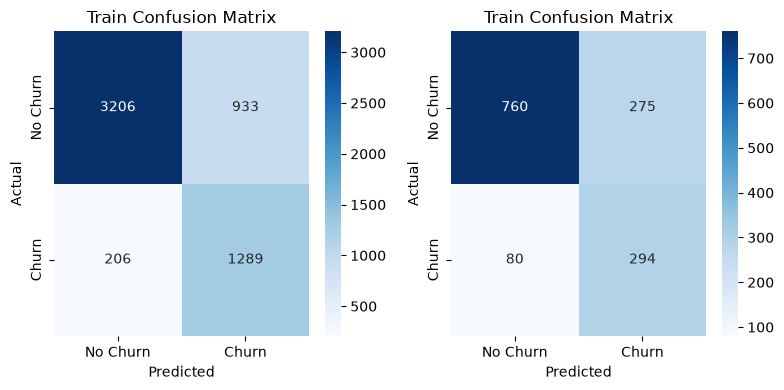

In [ ]:
cm_train=confusion_matrix(y_train, y_train_pred)
cm_test=confusion_matrix(y_test, y_test_pred)

fig,axes=plt.subplots(1,2, figsize=(8,4))
# Train
sns.heatmap(
    cm_train,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"],
    ax=axes[0]
)
axes[0].set_title("Train Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Test
sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"],
    ax=axes[1]
)
axes[1].set_title("Test Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()